# Fases 4 y 5 — Tamaño en centímetros con las fotos propias

Estimación del tamaño físico de la fruta a partir de una sola foto, con las 45 fotos del conjunto principal (`data/labels/anotaciones_propias.csv`). Especificación: `docs/TRASPASO.md` §4.4.

**Formulación.** La cámara estuvo a distancia fija (30 cm), así que la longitud real es proporcional a la longitud en píxeles:

$$\text{medida}_{cm} \approx k \cdot L_{px}, \qquad \hat k = \operatorname{mediana}_i\left(\frac{\text{medida}_{cm,i}}{L_{px,i}}\right).$$

- $L_{px}$ es el lado mayor del rectángulo de área mínima que contiene la máscara (`cv2.minAreaRect`), la misma magnitud que se midió con regla: diámetro mayor en manzana y guayaba, largo de punta a punta en banano.
- La mediana, a diferencia de la media o de los mínimos cuadrados, es robusta a fotos tomadas a una altura algo distinta.
- $\hat k$ se valida **dejando una fruta fuera** (`id_fruta`): las tres fotos de una fruta nunca se evalúan con un $\hat k$ ajustado con ellas.
- Las clases pequeño / mediano / grande se definen con los terciles de `medida_cm` dentro de cada fruta.

Todas las imágenes se reducen a 1024 px por el lado mayor (`read_image_max`), por lo que $\hat k$ solo es válido a esa escala.

In [1]:
import sys, json, math
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, cv2
from PIL import Image, ExifTags
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from fruitq.config import FIGURES, MODELS, RAW_PROPIAS, LABELS, SIZE_CLASSES
from fruitq.io import project_path, read_image_max
from fruitq.data import read_annotations
from fruitq.segmentation import fruit_on_uniform_background, largest_fruit
from fruitq.size import (characteristic_length, cross_validated_cm, equivalent_diameter,
                         fit_scale, fit_thresholds, size_class)

MAX_SIDE = 1024
FRUTAS = ["banano", "guayaba", "manzana"]
COLOR = {"banano": "#2a78d6", "guayaba": "#eb6834", "manzana": "#1baf7a"}
MARCA = {"banano": "o", "guayaba": "s", "manzana": "^"}

sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
def savefig(name):
    plt.savefig(FIGURES / f"{name}.pdf", bbox_inches="tight"); plt.savefig(FIGURES / f"{name}.png", bbox_inches="tight", dpi=150)

## 1. Medición en píxeles

Cada foto se segmenta con `fruit_on_uniform_background`, que excluye la sombra; si no detecta fruta se usa `largest_fruit`. Además de $L_{px}$ se calculan, para comparar, el diámetro equivalente $d = 2\sqrt{A/\pi}$ (definición inicial de la especificación para manzana y guayaba) y el diámetro de Feret máximo (mayor distancia entre dos puntos del contorno). El celular y la fecha se leen de los metadatos EXIF.

In [2]:
anot = read_annotations(LABELS / "anotaciones_propias.csv")
anot = anot[anot.conjunto == "principal"].reset_index(drop=True)
TAG = {v: k for k, v in ExifTags.TAGS.items()}

def exif(path):
    ex = Image.open(path).getexif()
    sub = ex.get_ifd(0x8769) if ex else {}
    fecha = sub.get(TAG["DateTimeOriginal"]) or ex.get(TAG["DateTime"]) or ""
    return (ex.get(TAG["Model"]) or "sin metadatos"), fecha[:10].replace(":", "-")

filas, sin_fondo_uniforme = [], []
for r in anot.itertuples():
    ruta = RAW_PROPIAS / r.archivo
    img = read_image_max(ruta, MAX_SIDE)
    reg = fruit_on_uniform_background(img)
    if reg is None:
        sin_fondo_uniforme.append(r.archivo); reg = largest_fruit(img)
    hull = cv2.convexHull(reg.contour).reshape(-1, 2).astype(float)
    feret = np.sqrt(((hull[:, None] - hull[None]) ** 2).sum(-1)).max()
    celular, fecha = exif(ruta)
    filas.append(dict(archivo=r.archivo, id_fruta=r.id_fruta, fruta=r.fruta, calidad=r.calidad, medida_cm=r.medida_cm,
                      celular=celular, fecha=fecha, L_px=characteristic_length(reg.contour),
                      d_eq_px=equivalent_diameter(reg.area), feret_px=feret))
tam = pd.DataFrame(filas)
print(f"{len(tam)} fotos medidas; segmentadas con largest_fruit: {sin_fondo_uniforme or 'ninguna'}")
tam.groupby("fruta")[["medida_cm", "L_px", "d_eq_px", "feret_px"]].agg(["min", "median", "max"]).round(1)

45 fotos medidas; segmentadas con largest_fruit: ninguna


medida_cm                L_px               d_eq_px                \
              min median   max    min median    max     min median    max   
fruta                                                                       
banano       13.5   14.0  15.0  314.6  338.1  509.8   165.7  184.9  262.7   
guayaba       6.7    7.0   9.0  135.4  166.1  226.7   130.9  150.4  170.4   
manzana       7.0    7.9   8.5  188.4  208.7  263.3   167.4  202.7  242.0   

        feret_px                
             min median    max  
fruta                           
banano     315.4  339.3  510.0  
guayaba    154.5  189.3  239.3  
manzana    199.8  225.5  288.4

## 2. Factor de escala y validación cruzada agrupada

In [3]:
variantes = {
    "Lado mayor del rectángulo mínimo (elegida)": tam.L_px,
    "Diámetro equivalente; banano: lado mayor": np.where(tam.fruta == "banano", tam.L_px, tam.d_eq_px),
    "Feret máximo": tam.feret_px,
}
filas = []
for nombre, L in variantes.items():
    pred = cross_validated_cm(tam.medida_cm, L, tam.id_fruta)
    err = np.abs(pred - tam.medida_cm)
    ratio = tam.medida_cm / L
    fila = {"medida en píxeles": nombre, "k (todas las fotos)": fit_scale(tam.medida_cm, L),
            "CV de medida/L (%)": 100 * ratio.std() / ratio.mean(), "EAM global (cm)": err.mean()}
    fila.update({f"EAM {f} (cm)": err[tam.fruta == f].mean() for f in FRUTAS})
    fila["error relativo medio (%)"] = 100 * (err / tam.medida_cm).mean()
    filas.append(fila)
comparacion = pd.DataFrame(filas).set_index("medida en píxeles")
comparacion.round(4)

,k (todas las fotos),CV de medida/L (%),EAM global (cm),EAM banano (cm),EAM guayaba (cm),EAM manzana (cm),error relativo medio (%)
medida en píxeles,,,,,,,
Lado mayor del rectángulo mínimo (elegida),0.0404,12.0067,0.9768,1.4892,0.6185,0.8228,9.8997
Diámetro equivalente; banano: lado mayor,0.0416,15.4451,1.1893,1.6077,1.1527,0.8075,12.2836
Feret máximo,0.0374,12.2576,1.0573,1.7768,0.5221,0.8728,10.2752


La variante elegida se fija por la **definición de la medida con regla** (diámetro mayor y largo de punta a punta), no por su error; las otras dos se muestran como comparación. EAM = error absoluto medio de la estimación validada (cada fruta estimada con un $\hat k$ que no la incluye).

In [4]:
K = fit_scale(tam.medida_cm, tam.L_px)                       # k final, con las 45 fotos, para la aplicación
tam["cm_estimado"] = cross_validated_cm(tam.medida_cm, tam.L_px, tam.id_fruta)
tam["error_cm"] = tam.cm_estimado - tam.medida_cm             # > 0: sobreestima
print(f"k = {K:.5f} cm/px a {MAX_SIDE} px por el lado mayor")
resumen = tam.groupby("fruta").apply(lambda g: pd.Series({
    "fotos": len(g), "EAM (cm)": g.error_cm.abs().mean(), "sesgo medio (cm)": g.error_cm.mean(),
    "error máximo (cm)": g.error_cm.abs().max(), "error relativo medio (%)": 100 * (g.error_cm.abs() / g.medida_cm).mean()}),
    include_groups=False)
resumen.loc["todas"] = [len(tam), tam.error_cm.abs().mean(), tam.error_cm.mean(), tam.error_cm.abs().max(),
                        100 * (tam.error_cm.abs() / tam.medida_cm).mean()]
resumen.round(3)

k = 0.04041 cm/px a 1024 px por el lado mayor


,fotos,EAM (cm),sesgo medio (cm),error máximo (cm),error relativo medio (%)
fruta,,,,,
banano,15.0,1.489,0.762,6.648,10.436
guayaba,15.0,0.619,-0.450,1.474,8.452
manzana,15.0,0.823,0.730,2.799,10.810
todas,45.0,0.977,0.348,6.648,9.900


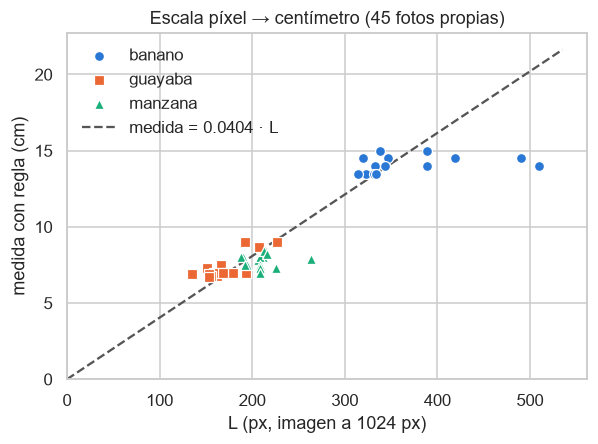

In [5]:
fig, ax = plt.subplots(figsize=(5.6, 4.2))
for f in FRUTAS:
    s = tam[tam.fruta == f]
    ax.scatter(s.L_px, s.medida_cm, s=42, marker=MARCA[f], color=COLOR[f], edgecolor="white", linewidth=0.8, label=f, zorder=3)
x = np.linspace(0, tam.L_px.max() * 1.05, 50)
ax.plot(x, K * x, color="#555555", lw=1.5, ls="--", label=f"medida = {K:.4f} · L", zorder=2)
ax.set_xlim(0, None); ax.set_ylim(0, None)
ax.set_xlabel(f"L (px, imagen a {MAX_SIDE} px)"); ax.set_ylabel("medida con regla (cm)")
ax.set_title("Escala píxel → centímetro (45 fotos propias)")
ax.legend(frameon=False)
plt.tight_layout(); savefig("tamano_escala"); plt.show()

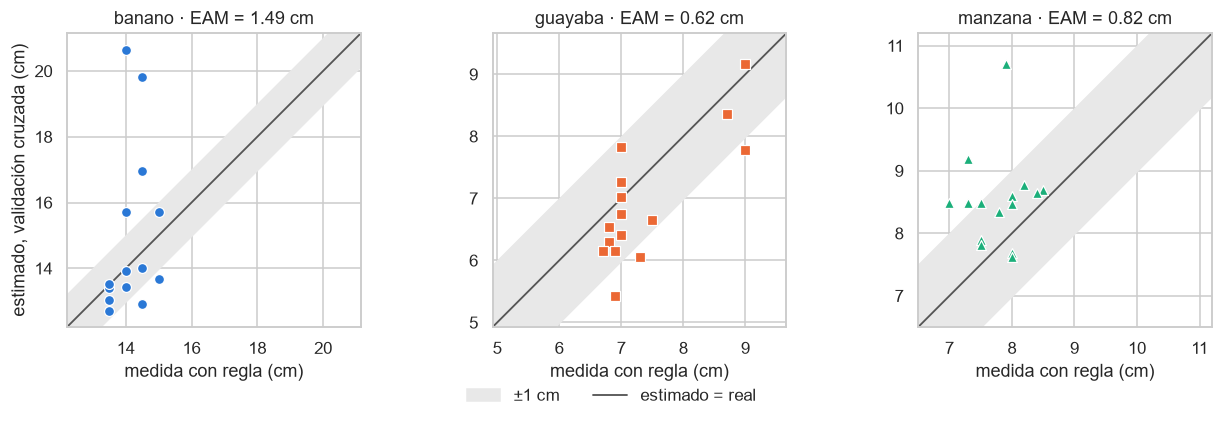

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, f in zip(axes, FRUTAS):
    s = tam[tam.fruta == f]
    lo, hi = min(s.medida_cm.min(), s.cm_estimado.min()) - 0.5, max(s.medida_cm.max(), s.cm_estimado.max()) + 0.5
    ax.fill_between([lo, hi], [lo - 1, hi - 1], [lo + 1, hi + 1], color="#e8e8e8", zorder=1, label="±1 cm")
    ax.plot([lo, hi], [lo, hi], color="#555555", lw=1.2, zorder=2, label="estimado = real")
    ax.scatter(s.medida_cm, s.cm_estimado, s=42, marker=MARCA[f], color=COLOR[f], edgecolor="white", linewidth=0.8, zorder=3)
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect("equal")
    ax.set_title(f"{f} · EAM = {s.error_cm.abs().mean():.2f} cm"); ax.set_xlabel("medida con regla (cm)")
axes[0].set_ylabel("estimado, validación cruzada (cm)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 0))
plt.tight_layout(rect=(0, 0.07, 1, 1)); savefig("tamano_estimado_vs_real"); plt.show()

### Fuentes del error: sesión de captura y celular

Cada combinación fruta × calidad se fotografió en una sesión distinta. Un sesgo medio grande y del mismo signo en toda una sesión indica que la cámara no quedó exactamente a 30 cm: si quedó más cerca, la fruta ocupa más píxeles y su tamaño se **sobreestima**. Celular y sesión están confundidos (ver `docs/TRASPASO.md` §4.1), así que esta tabla describe el error, pero no separa sus causas.

In [7]:
sesion = tam.groupby(["fruta", "calidad", "celular", "fecha"]).agg(
    fotos=("archivo", "size"), L_px_mediana=("L_px", "median"), medida_cm_media=("medida_cm", "mean"),
    sesgo_cm=("error_cm", "mean"), EAM_cm=("error_cm", lambda e: e.abs().mean())).round(3)
sesion

fotos  L_px_mediana  \
fruta   calidad celular        fecha                             
banano  buena   moto g(9) play 2026-11-18      5       419.367   
        mala    moto g(9) play 2026-11-18      5       331.999   
        regular iPhone 13      2026-11-16      5       338.107   
guayaba buena   iPhone 13      2026-11-16      5       168.495   
        mala    moto g(9) play 2026-11-18      5       155.871   
        regular iPhone 13      2026-11-16      5       179.780   
manzana buena   iPhone 13      2026-11-16      5       208.858   
        mala    moto g(9) play 2026-11-23      5       215.832   
        regular sin metadatos                  5       208.496   

                                           medida_cm_media  sesgo_cm  EAM_cm  
fruta   calidad celular        fecha                                          
banano  buena   moto g(9) play 2026-11-18            14.40     3.370   3.370  
        mala    moto g(9) play 2026-11-18            13.70    -0.496   0.510  
        regular iPhone 13      2026-11-16            14.20    -0.587   0.587  
guayaba buena   iPhone 13      2026-11-16             7.50    -0.302   0.372  
        mala    moto g(9) play 2026-11-18             7.18    -0.624   0.624  
        regular iPhone 13      2026-11-16             7.44    -0.424   0.859  
manzana buena   iPhone 13      2026-11-16             7.90     0.357   0.481  
        mala    moto g(9) play 2026-11-23             7.64     1.456   1.456  
        regular sin metadatos                         7.84     0.378   0.532

## 3. Clases de tamaño por terciles

Para cada fruta, los terciles $t_1, t_2$ de `medida_cm` definen la clase real (pequeño si $x < t_1$, mediano si $t_1 \le x < t_2$, grande si $x \ge t_2$). La clase estimada aplica los mismos umbrales a la estimación validada en cm. La exactitud se compara con la de asignar siempre la clase más frecuente.

In [8]:
terciles = {f: fit_thresholds(tam.loc[tam.fruta == f, "medida_cm"]) for f in FRUTAS}
tam["clase_real"] = [size_class(v, terciles[f]) for v, f in zip(tam.medida_cm, tam.fruta)]
tam["clase_estimada"] = [size_class(v, terciles[f]) for v, f in zip(tam.cm_estimado, tam.fruta)]
orden = {c: i for i, c in enumerate(SIZE_CLASSES)}
tam["salto"] = (tam.clase_estimada.map(orden) - tam.clase_real.map(orden)).abs()

clases = tam.groupby("fruta").apply(lambda g: pd.Series({
    "t1 (cm)": terciles[g.name][0], "t2 (cm)": terciles[g.name][1], "rango medido (cm)": g.medida_cm.max() - g.medida_cm.min(),
    "exactitud": (g.clase_real == g.clase_estimada).mean(), "error de dos clases": (g.salto == 2).mean(),
    "clase más frecuente": g.clase_real.value_counts(normalize=True).iloc[0]}), include_groups=False)
clases.loc["todas"] = [np.nan, np.nan, np.nan, (tam.clase_real == tam.clase_estimada).mean(), (tam.salto == 2).mean(),
                       np.nan]
clases.round(3)

,t1 (cm),t2 (cm),rango medido (cm),exactitud,error de dos clases,clase más frecuente
fruta,,,,,,
banano,13.833,14.5,1.5,0.600,0.133,0.400
guayaba,6.967,7.1,2.3,0.600,0.133,0.333
manzana,7.500,8.0,1.5,0.467,0.200,0.467
todas,NaN,NaN,NaN,0.556,0.156,NaN


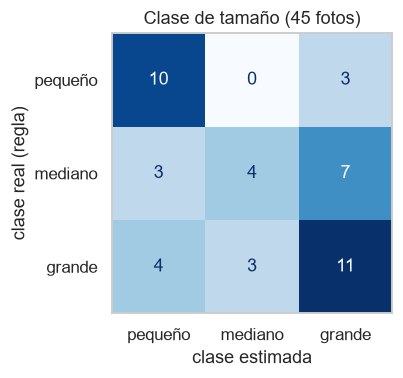

In [9]:
fig, ax = plt.subplots(figsize=(4.2, 3.6))
ConfusionMatrixDisplay(confusion_matrix(tam.clase_real, tam.clase_estimada, labels=SIZE_CLASSES),
                       display_labels=["pequeño", "mediano", "grande"]).plot(cmap="Blues", colorbar=False, ax=ax)
ax.grid(False); ax.set_xlabel("clase estimada"); ax.set_ylabel("clase real (regla)"); ax.set_title("Clase de tamaño (45 fotos)")
plt.tight_layout(); savefig("tamano_clases"); plt.show()

## 4. Parámetros para la aplicación

Se guardan en `models/umbrales.json`, sección `tamano`. La sección `calidad` (umbrales $t_1, t_2$ sobre $P(\text{mala} \mid x)$, tarea §4.3) se agrega en el mismo archivo sin borrar esta. La tabla por foto queda en `reports/tabla_tamano_fotos_propias.csv`.

In [10]:
ruta = MODELS / "umbrales.json"
params = json.loads(ruta.read_text(encoding="utf-8")) if ruta.exists() else {}
params["tamano"] = {
    "descripcion": "medida_cm = k * L_px; L_px = lado mayor de cv2.minAreaRect sobre la máscara de fruit_on_uniform_background",
    "max_side_px": MAX_SIDE,
    "k_cm_por_px": round(K, 6),
    "terciles_cm": {f: [round(t, 3) for t in terciles[f]] for f in FRUTAS},
    "clases": SIZE_CLASSES,
    "validacion": {"esquema": "dejar una fruta fuera (id_fruta)", "fotos": int(len(tam)),
                   "eam_cm": {f: round(float(tam.loc[tam.fruta == f, "error_cm"].abs().mean()), 3) for f in FRUTAS},
                   "exactitud_clase": round(float((tam.clase_real == tam.clase_estimada).mean()), 3)},
}
ruta.write_text(json.dumps(params, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
cols = ["archivo", "id_fruta", "fruta", "calidad", "celular", "fecha", "medida_cm", "L_px", "d_eq_px", "feret_px",
        "cm_estimado", "error_cm", "clase_real", "clase_estimada"]
tam[cols].round(3).to_csv(ROOT / "reports" / "tabla_tamano_fotos_propias.csv", index=False)
print(json.dumps(params["tamano"], indent=2, ensure_ascii=False))

{
  "descripcion": "medida_cm = k * L_px; L_px = lado mayor de cv2.minAreaRect sobre la máscara de fruit_on_uniform_background",
  "max_side_px": 1024,
  "k_cm_por_px": 0.040413,
  "terciles_cm": {
    "banano": [
      13.833,
      14.5
    ],
    "guayaba": [
      6.967,
      7.1
    ],
    "manzana": [
      7.5,
      8.0
    ]
  },
  "clases": [
    "pequeno",
    "mediano",
    "grande"
  ],
  "validacion": {
    "esquema": "dejar una fruta fuera (id_fruta)",
    "fotos": 45,
    "eam_cm": {
      "banano": 1.489,
      "guayaba": 0.619,
      "manzana": 0.823
    },
    "exactitud_clase": 0.556
  }
}
